# Surface vessel (ODE) — the physics-based recipe

Our **ODE benchmark**, and the running example for the whole course. We walk the
four-step recipe — **1. derive → 2. write & analyze → 3. solve → 4. analyze** — and then
probe four *aspects of the method itself*:

1. the **maneuvers** the full 3-DOF model produces,
2. the **order of accuracy** of the RK4 integrator (vs Euler and RK2),
3. **stability** — eigenvalues and coast-down decay,
4. **sensitivity to the uncertain ("amber") coefficients** — the very terms the later
   data-driven, PINN, CoSTA and discovery modules will identify or correct.

The 3-DOF model lives in `pyutils/benchmarks/vessel.py`, so every later module re-uses the
*same* ground truth.

### Setup — libraries, plotting style, and the shared vessel model

Import NumPy and Matplotlib, apply the shared course plotting style, and import the 3-DOF vessel
benchmark from `pyutils.benchmarks.vessel` — the *same* module every later (data-driven, PINN,
CoSTA, discovery) module imports, so they are all judged against one ground truth. `FIG` is the
directory for the dual light/dark figures and `np.random.seed(0)` fixes reproducibility. This cell
only prepares the environment; no dynamics are evaluated yet.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(os.path.join('..', '..')))  # -> python/
import numpy as np
import matplotlib.pyplot as plt
from pyutils import set_plot_style; set_plot_style()
from pyutils.benchmarks import vessel

FIG = os.path.abspath(os.path.join('..', 'figures')); os.makedirs(FIG, exist_ok=True)
from pyutils import save_dual, fg
np.random.seed(0)

*No numerical output — this cell only sets up imports, the plot style, and the figure directory.*
It leaves the `vessel` module (`VesselParams`, `simulate`, `turning_circle`, `zigzag`,
`linear_stability`) and the `save_dual`/`fg` plotting helpers in scope for everything that follows.

### Parameters — change these and re-run the notebook

The vessel coefficients and the maneuver inputs live here and nowhere else: every simulation, sweep, reference line and figure annotation below reads them from `p`, `surge`, `yaw_tc`, `yaw_zz`, `psi_switch`, `t_end` and `dt`. Try e.g. `vessel.VesselParams(Dv=60.0, Y_vdot=-20.0)` or a different switching heading for the zig-zag. *The prose between the cells narrates the **default** run; if you change a parameter the numbers quoted in the text will no longer match, but every print-out, figure, annotation and saved reference file will follow your change.*

In [2]:
# ---- Parameters (edit these, then Run All) ------------------------------
p = vessel.VesselParams()          # e.g. vessel.VesselParams(Dv=60.0, Y_vdot=-20.0)
surge      = 200.0                 # constant surge thrust [N] used by both maneuvers
yaw_tc     = 80.0                  # yaw moment [N m] for the turning circle
yaw_zz     = 120.0                 # yaw moment [N m] for the zig-zag (sign flips)
psi_switch = 0.35                  # zig-zag heading at which the yaw moment flips [rad]
t_end, dt  = 60.0, 0.02            # simulation horizon [s] and RK4 step [s]
print(p)


VesselParams(m=50.0, Iz=20.0, X_udot=-5.0, Y_vdot=-30.0, N_rdot=-10.0, Du=10.0, Dv=40.0, Dr=15.0, Xuu=5.0, Yvv=40.0, Nrr=10.0)


## Step 1 — Derive

Newton–Euler for a rigid body in the horizontal plane (surge–sway–yaw), in the Fossen form

$$\dot{\boldsymbol{\eta}} = \mathbf{R}(\psi)\,\boldsymbol{\nu},\qquad
\mathbf{M}\dot{\boldsymbol{\nu}} + \mathbf{C}(\boldsymbol{\nu})\boldsymbol{\nu}
+ \mathbf{D}(\boldsymbol{\nu})\boldsymbol{\nu} = \boldsymbol{\tau},$$

with pose $\boldsymbol{\eta}=[x,y,\psi]^\top$ (NED) and body velocity
$\boldsymbol{\nu}=[u,v,r]^\top$. The rigid-body inertia is *known*; the **added mass**
(in $\mathbf{M}$) and **damping** (in $\mathbf{D}$) are the *uncertain* terms.

**The matrices and default coefficients** (`VesselParams`). The mass matrix is diagonal for this
trimmed hull, $\mathbf{M}=\mathrm{diag}(m-X_{\dot u},\,m-Y_{\dot v},\,I_z-N_{\dot r})$, with
rigid-body $m=50$, $I_z=20$ and (uncertain, negative) added mass
$X_{\dot u}=-5,\;Y_{\dot v}=-30,\;N_{\dot r}=-10$. The damping
$\mathbf{D}(\boldsymbol{\nu})=\mathrm{diag}(d_u+X_{|u|u}|u|,\;d_v+Y_{|v|v}|v|,\;d_r+N_{|r|r}|r|)$ is
linear $(d_u,d_v,d_r)=(10,40,15)$ plus quadratic $(X_{|u|u},Y_{|v|v},N_{|r|r})=(5,40,10)$, and the
skew Coriolis–centripetal $\mathbf{C}(\boldsymbol{\nu})$ is built from the same masses. This cell
prints $\mathbf{M}$, and $\mathbf{C}$ and $\mathbf{D}$ evaluated at $\boldsymbol{\nu}=[1,0.2,0.1]$.

In [3]:
print('M =\n', p.M())
print('\nC(nu) at nu=[1, 0.2, 0.1] =\n', p.C(np.array([1.0, 0.2, 0.1])))
print('\nD(nu) at nu=[1, 0.2, 0.1] =\n', p.D(np.array([1.0, 0.2, 0.1])))

M =
 [[55.  0.  0.]
 [ 0. 80.  0.]
 [ 0.  0. 30.]]

C(nu) at nu=[1, 0.2, 0.1] =
 [[  0.   0. -16.]
 [  0.   0.  55.]
 [ 16. -55.   0.]]

D(nu) at nu=[1, 0.2, 0.1] =
 [[15.  0.  0.]
 [ 0. 48.  0.]
 [ 0.  0. 16.]]


$\mathbf{M}=\mathrm{diag}(55,80,30)$ — the added mass has raised the surge/sway/yaw inertias from
their rigid-body values $(50,50,20)$. At $\boldsymbol{\nu}=[1,0.2,0.1]$ the Coriolis matrix is
skew-symmetric with nonzero couplings $C_{13}=-m_{22}v=-16$ and $C_{23}=m_{11}u=55$ (a turning ship
feels a surge/sway cross-force), and the damping is $\mathbf{D}=\mathrm{diag}(15,48,16)$: each entry
is the linear drag plus the speed-proportional quadratic part ($15=10+5\cdot1$, $48=40+40\cdot0.2$,
$16=15+10\cdot0.1$). These matrices are the amber coefficients later modules must pin down.

## Step 2 — Write & analyze: stability

Stack to a first-order state $\boldsymbol{z}=[\boldsymbol{\eta},\boldsymbol{\nu}]$ and check
**eigenvalue stability** of the velocity dynamics linearized at rest,
$\dot{\boldsymbol{\nu}}\approx -\mathbf{M}^{-1}\mathbf{D}(\mathbf{0})\,\boldsymbol{\nu}$ —
the ODE analogue of the von Neumann test used for the PDE schemes. At rest the quadratic drag
vanishes, so $\mathbf{D}(\mathbf{0})=\mathrm{diag}(10,40,15)$ and the linearized system is diagonal
with rates $-d_{ii}/m_{ii}$; all eigenvalues should lie in the open left half-plane, making the
open-loop vessel asymptotically stable. `linear_stability(p)` returns these eigenvalues.

In [4]:
eig = vessel.linear_stability(p)
print('eigenvalues:', np.round(eig, 4))
print('decay rates (1/s):', np.round(-eig.real, 4))
print('asymptotically stable:', bool(np.all(eig.real < 0)))

eigenvalues: [-0.1818 -0.5    -0.5   ]
decay rates (1/s): [0.1818 0.5    0.5   ]
asymptotically stable: True


The eigenvalues are $\{-0.182,\,-0.5,\,-0.5\}$ — all real, all negative, so the coasting vessel is
**asymptotically stable** (`True`). They are exactly the diagonal decay rates $-d_u/m_{11}=-10/55$,
$-d_v/m_{22}=-40/80$ and $-d_r/m_{33}=-15/30$: surge relaxes slowest ($\tau\approx5.5$ s) because it
is the least-damped DOF, while sway and yaw decay in $\approx2$ s. These same three rates reappear as
the coast-down curves in Aspect 3.

## Step 3 — Solve, and aspect 1: the maneuvers

Integrate the IVP with the module's fixed-step **RK4** solver from rest, $\boldsymbol{z}(0)=\mathbf{0}$,
over $t\in[0,t_{\text{end}}]$ (default $60$ s) at $\Delta t=0.02$ s, under the two standard maneuvers (thrusts and switching angle from the parameter cell):

* **turning circle** — a constant thrust $\boldsymbol{\tau}=[200,\,0,\,80]$ (constant surge force and
  yaw moment);
* **zig-zag** — a $20/20$-style test, $\boldsymbol{\tau}=[200,\,0,\,\pm120]$ whose yaw moment **flips
  sign** each time the heading crosses $\psi=\pm0.35$ rad.

The full 3-DOF state lets us read the NED path $(x,y)$, the body velocities $u,v,r$, and the heading
$\psi(t)$ together. The cell also prints the turning-circle final pose.

turning-circle final pose [x,y,psi]: [  1.85   2.13 143.97]


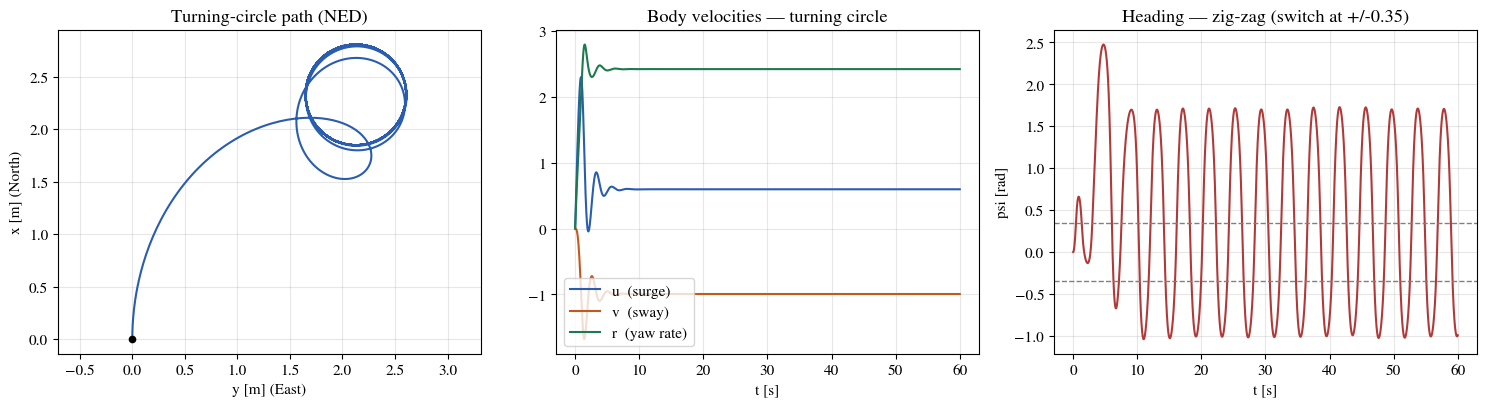

In [5]:
t_tc, Z_tc = vessel.simulate(vessel.turning_circle(surge, yaw_tc),        t_end=t_end, dt=dt, p=p)
t_zz, Z_zz = vessel.simulate(vessel.zigzag(surge, yaw_zz, psi_switch),   t_end=t_end, dt=dt, p=p)
print('turning-circle final pose [x,y,psi]:', np.round(Z_tc[-1, :3], 2))

def plot_vessel_maneuvers():
    fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
    ax[0].plot(Z_tc[:, 1], Z_tc[:, 0], color='C0')
    ax[0].plot(0, 0, '.', color=fg(), ms=9)
    ax[0].set(xlabel='y [m] (East)', ylabel='x [m] (North)',
              title='Turning-circle path (NED)'); ax[0].axis('equal')
    for j, lab in enumerate(['u  (surge)', 'v  (sway)', 'r  (yaw rate)']):
        ax[1].plot(t_tc, Z_tc[:, 3 + j], label=lab)
    ax[1].set(xlabel='t [s]', title='Body velocities — turning circle'); ax[1].legend()
    ax[2].plot(t_zz, Z_zz[:, 2], color='C3')
    ax[2].axhline(psi_switch, ls='--', c='gray', lw=1); ax[2].axhline(-psi_switch, ls='--', c='gray', lw=1)
    ax[2].set(xlabel='t [s]', ylabel='psi [rad]', title=f'Heading — zig-zag (switch at +/-{psi_switch:g})')
    plt.tight_layout()

save_dual(plot_vessel_maneuvers, 'vessel_maneuvers', FIG)
plt.show()

The three panels tell the story. **Left (NED path):** from the origin (dot) the vessel spirals out
and locks onto a tight, constant-radius turning circle centred near $(x,y)\approx(2.1,2.1)$ m.
**Middle (body velocities):** after a short transient — surge overshoots then settles to
$u\approx0.6$, sway to $v\approx-1.0$, yaw rate to $r\approx2.4$ rad/s — all three reach steady state
by $\sim10$ s, and steady $u,r$ is precisely what makes a circle. **Right (zig-zag heading):** the
heading overshoots each $\pm0.35$ rad switch line hugely (first peak $\approx2.5$ rad) because yaw
inertia carries $\psi$ well past the line before the reversed moment bites, then settles into a
periodic oscillation between about $+1.7$ and $-1.0$ rad. The printed final pose
$[x,y,\psi]=[1.85,\,2.13,\,143.97]$ confirms the loop: $\psi\approx144$ rad is the *unwrapped* heading
— roughly $23$ full turns around the circle in 60 s at $r\approx2.4$ rad/s. This is a first look at
the rotational dynamics the later data-driven modules must reproduce.

## Aspect 2 — Order of accuracy of the integrator

RK4 is *fourth-order*: halving the step should cut the error by $\sim 2^4=16$. Using the
turning-circle input from rest over $t\in[0,10]$ s, we integrate with a notebook-local
Euler/RK2/RK4 loop at step sizes $\Delta t\in\{0.2,0.1,0.05,0.025,0.0125,0.00625\}$ and measure the
final-state error against a fine $\Delta t=10^{-4}$ RK4 reference. Fitting the log–log slopes on the
small-step range ($\Delta t\le0.05$) should recover the theoretical orders 1 (Euler), 2 (RK2) and
4 (RK4).

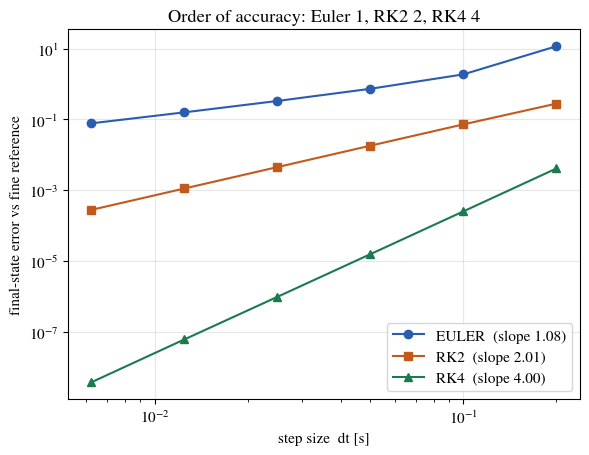

fitted slopes: {'euler': 1.08, 'rk2': 2.01, 'rk4': 4.0}


In [6]:
def integrate(method, dt, tau_fn, z0, t_end, p):
    # Notebook-local fixed-step integrator so we can compare Euler / RK2 / RK4.
    n = int(round(t_end / dt))
    z = np.asarray(z0, float).copy()
    f = lambda zz, tt: vessel.state_derivative(zz, tau_fn(tt, zz), p)
    for k in range(n):
        tk = k * dt
        if method == 'euler':
            z = z + dt * f(z, tk)
        elif method == 'rk2':
            k1 = f(z, tk); k2 = f(z + 0.5 * dt * k1, tk + 0.5 * dt)
            z = z + dt * k2
        else:  # rk4
            k1 = f(z, tk); k2 = f(z + 0.5 * dt * k1, tk + 0.5 * dt)
            k3 = f(z + 0.5 * dt * k2, tk + 0.5 * dt); k4 = f(z + dt * k3, tk + dt)
            z = z + (dt / 6.0) * (k1 + 2 * k2 + 2 * k3 + k4)
    return z

tau_fn, z0, T = vessel.turning_circle(surge, yaw_tc), np.zeros(6), 10.0
z_ref = integrate('rk4', 1e-4, tau_fn, z0, T, p)        # fine reference
dts = np.array([0.2, 0.1, 0.05, 0.025, 0.0125, 0.00625])
errs = {m: np.array([np.linalg.norm(integrate(m, dt, tau_fn, z0, T, p) - z_ref)
                     for dt in dts]) for m in ['euler', 'rk2', 'rk4']}
mask = dts <= 0.05   # fit the order on the asymptotic (small-step) range
slopes = {m: np.polyfit(np.log(dts[mask]), np.log(errs[m][mask]), 1)[0] for m in errs}

def plot_vessel_rk4_order():
    fig, ax = plt.subplots(figsize=(6.6, 4.8))
    for m, mk in zip(['euler', 'rk2', 'rk4'], ['o', 's', '^']):
        ax.loglog(dts, errs[m], mk + '-', label=f'{m.upper()}  (slope {slopes[m]:.2f})')
    ax.set(xlabel='step size  dt [s]', ylabel='final-state error vs fine reference',
           title='Order of accuracy: Euler 1, RK2 2, RK4 4')
    ax.legend()

save_dual(plot_vessel_rk4_order, 'vessel_rk4_order', FIG)
plt.show()
print('fitted slopes:', {m: round(float(slopes[m]), 2) for m in slopes})

The fitted slopes are **Euler 1.08, RK2 2.01, RK4 4.00** — the textbook orders, recovered cleanly.
On the log–log plot the RK4 line is by far the steepest *and* the lowest: at $\Delta t=0.0125$ its
final-state error is $\sim10^{-7}$ against $\sim10^{-4}$ for RK2 and $\sim10^{-1}$ for Euler. This is
why a *single* RK4 trajectory is an honest ground truth for the surrogate, PINN and operator methods
later — their few-percent errors are measured against a solution whose discretization error is
negligible.

## Aspect 3 — Stability and coast-down decay

Turn the thrust off ($\boldsymbol{\tau}=\mathbf{0}$) and let each velocity component coast to rest on
its own, exciting one DOF at a time (initial $u=3.0$, then $v=2.0$, then $r=1.5$, over $t\in[0,20]$ s)
so the decays are uncoupled. The rates are exactly the eigenvalues from Step 2; the dashed lines are
the *linear* prediction $e^{\lambda t}$. Early on the quadratic drag makes the real decay faster,
relaxing onto the linear rate as the speed drops — a clean picture of linear vs nonlinear damping.
The left panel re-plots the eigenvalues in the complex plane.

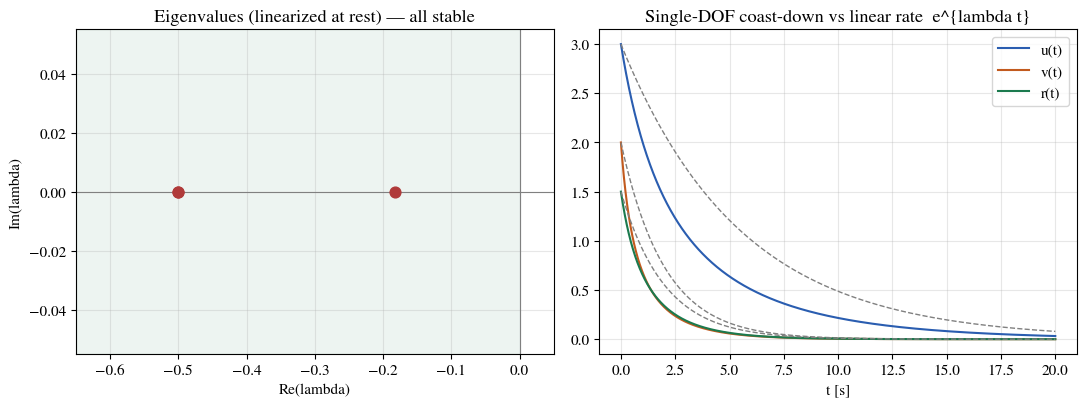

In [7]:
def plot_vessel_stability():
    fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
    ax[0].axhline(0, c='gray', lw=0.8); ax[0].axvline(0, c='gray', lw=0.8)
    xlo = eig.real.min() * 1.3
    ax[0].axvspan(xlo, 0, color='C2', alpha=0.08)
    ax[0].scatter(eig.real, eig.imag, c='C3', s=60, zorder=3)
    ax[0].set(xlim=(xlo, 0.05), xlabel='Re(lambda)', ylabel='Im(lambda)',
              title='Eigenvalues (linearized at rest) — all stable')
    # Independent single-DOF coast-downs: each isolates one decay rate cleanly.
    # Linear rate per DOF straight from the diagonals (independent of eigenvalue ordering).
    M0, D0 = np.diag(p.M()), np.diag(p.D(np.zeros(3)))
    for j, (lab, mag) in enumerate([('u', 3.0), ('v', 2.0), ('r', 1.5)]):
        z0c = np.zeros(6); z0c[3 + j] = mag
        tc, Zc = vessel.simulate(lambda t, z: np.zeros(3), z0=z0c, t_end=20.0, dt=0.01, p=p)
        ax[1].plot(tc, Zc[:, 3 + j], color=f'C{j}', label=f'{lab}(t)')
        ax[1].plot(tc, mag * np.exp(-D0[j] / M0[j] * tc), '--', color='gray', lw=1)
    ax[1].set(xlabel='t [s]', title='Single-DOF coast-down vs linear rate  e^{lambda t}')
    ax[1].legend(); plt.tight_layout()

save_dual(plot_vessel_stability, 'vessel_stability', FIG)
plt.show()

**Left:** all three eigenvalues sit on the negative real axis (two coincide at $-0.5$, one at
$-0.182$) inside the shaded stable half-plane — the picture behind the `True` from Step 2.
**Right:** each coast-down (solid) starts *below* its linear prediction $e^{\lambda t}$ (dashed) and
decays faster at first, because at high speed the quadratic drag adds to the linear damping; as the
velocity shrinks the quadratic term fades and the curve relaxes onto the linear rate. Surge $u(t)$
(slowest, rate $0.182$) is still visibly nonzero at $20$ s, while sway and yaw (rate $0.5$) have
essentially vanished by $\sim8$ s.

## Aspect 4 — Sensitivity to the uncertain coefficients

The trajectory is only as trustworthy as the hydrodynamic coefficients. We re-run the same
turning-circle maneuver while sweeping the (uncertain) **sway damping** $D_v\in\{\tfrac12,1,2\}\times D_v$
(default $D_v=40$, so $\{20,40,80\}$) and **sway added mass** $Y_{\dot v}\in\{Y_{\dot v}-20,\,Y_{\dot v},\,Y_{\dot v}+20\}$ (default $-30$, so $\{-50,-30,-10\}$), one at a time — every other coefficient is taken from `p`.
Each visibly changes the turning circle — its radius, centre and how fast it settles. These are the
"amber" coefficients: known only approximately, and exactly what the data-driven and hybrid-model
modules identify from data, correct with a learned source term, or rediscover symbolically.

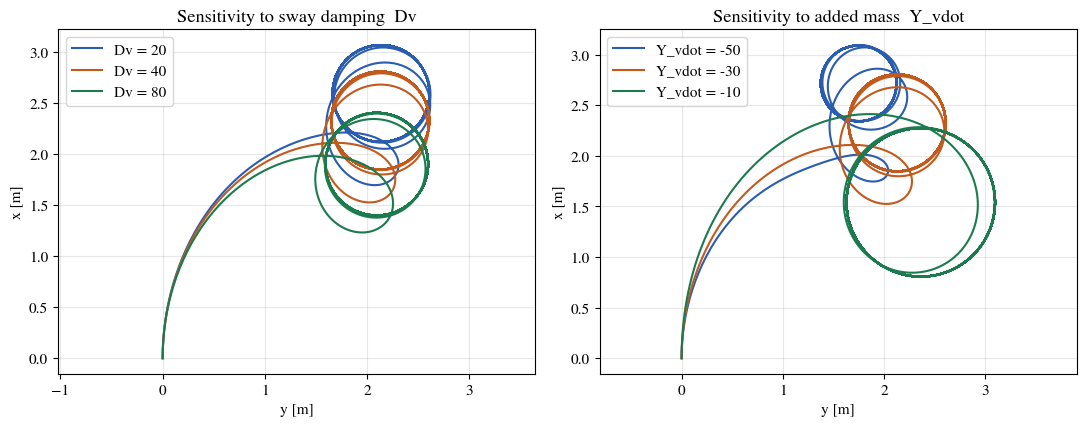

In [8]:
from dataclasses import replace

def plot_vessel_sensitivity():
    fig, ax = plt.subplots(1, 2, figsize=(11, 4.4))
    for Dv in [0.5*p.Dv, p.Dv, 2*p.Dv]:
        _, Z = vessel.simulate(vessel.turning_circle(surge, yaw_tc), t_end=t_end, dt=dt,
                               p=replace(p, Dv=Dv))            # all other coefficients from p
        ax[0].plot(Z[:, 1], Z[:, 0], label=f'Dv = {Dv:g}')
    ax[0].set(xlabel='y [m]', ylabel='x [m]', title='Sensitivity to sway damping  Dv')
    ax[0].legend(); ax[0].axis('equal')
    for Yvd in [p.Y_vdot - 20, p.Y_vdot, p.Y_vdot + 20]:
        _, Z = vessel.simulate(vessel.turning_circle(surge, yaw_tc), t_end=t_end, dt=dt,
                               p=replace(p, Y_vdot=Yvd))
        ax[1].plot(Z[:, 1], Z[:, 0], label=f'Y_vdot = {Yvd:g}')
    ax[1].set(xlabel='y [m]', ylabel='x [m]', title='Sensitivity to added mass  Y_vdot')
    ax[1].legend(); ax[1].axis('equal')
    plt.tight_layout()

save_dual(plot_vessel_sensitivity, 'vessel_sensitivity', FIG)
plt.show()


Both sweeps move the turning circle substantially. **Left ($D_v$):** more sway damping tightens and
lowers the settled circle — $D_v=80$ (green) sits well below and inside $D_v=20$ (blue), which loops
highest (to $x\approx3.05$ m). **Right ($Y_{\dot v}$):** less added mass makes the vessel more
maneuverable — $Y_{\dot v}=-10$ (green) traces a markedly *larger* circle reaching $y\approx3.1$ m,
while $Y_{\dot v}=-50$ (blue) turns tighter and higher. A handful of towing-tank coefficients we do
not know exactly shift the path by tens of percent — the concrete motivation for identifying or
correcting them in the modules that follow.

**Hand-off.** A first-principles model gives a trustworthy, interpretable
trajectory — but only as good as its amber coefficients, and re-deriving it for every new
vessel is costly. That gap is the rest of the course. The next cell exports the turning-circle
reference — the time vector `t` and the full state history `Z` (columns $[x,y,\psi,u,v,r]$) — to
`../data/vessel_reference.npz` so the downstream (DDM, PINN, CoSTA, discovery) modules judge
themselves against this exact run.

In [9]:
os.makedirs('../data', exist_ok=True)
np.savez('../data/vessel_reference.npz', t=t_tc, Z=Z_tc, maneuver='turning_circle')
print('saved ../data/vessel_reference.npz   shape', Z_tc.shape)

saved ../data/vessel_reference.npz   shape (3001, 6)


*The save succeeds:* `vessel_reference.npz` holds the turning-circle run as an array of shape
$(3001,6)$ — $3001$ time samples ($60$ s at $\Delta t=0.02$ s, plus the initial point) $\times$ the
six state components $[x,y,\psi,u,v,r]$. This single file is the shared ground truth the rest of the
course is measured against.